# SubPOP test set: released vs fine-tuned Kev

The test set is SubPOP's evaluation split (`subpop_eval`): 106 US General Social Survey questions, each answered by up to 22 US subpopulations (e.g. all Democrats, all Black respondents), 2,332 question rows. None of it was used in training, and questions that ISSP also asks are left out (`data/subpop/README.md`). The fine-tuned model was trained on all ISSP years (2015–2024); its best step was picked on the calibration set (`subpop100`).

For every question row, the model's predicted answer shares are compared with the group's observed shares:

- **KL divergence** (bits) and **JS divergence**: for every question; 0 = identical.
- **Wasserstein distance** as % of the scale range: for Likert (`score`) questions only, since it needs ordered answers; 0 = identical.

**No temperature anywhere, not even post hoc.** Every model is scored on its raw distribution (softmax of its scores, T = 1): no temperature is fitted or applied, on the calibration set or any other, because rescaling would only hide how well the model fits (`data/issp2020/DECISIONS.md`, 11).

There is no human benchmark: SubPOP gives only answer shares, not how many people answered, so the sampling error cannot be computed.

In [40]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import torch

sys.path.insert(0, "kev")
from kev.checkpoint import LoadOptions, load
import train_issp   # the test set, prediction and error measures used in training

MODELS = {
    # "Kev 0.8B released": "jaredpalmer/kev-0.8b",
    "Kev 0.8B fine-tuned": "runs/issp-all-0.8b-v11/best", 
}
TEST = train_issp.TEST_DATASET
test_records = train_issp.read_records(TEST)
sum(len(r["questions"]) for r in test_records)   # question rows in the test set

2332

## Model predictions

A model's predictions are computed once and saved in `runs/predictions/`; later runs load them. They are recomputed when the checkpoint is retrained or the test rows change.

In [41]:
CACHE = Path("runs/predictions")   # saved predictions: runs/predictions/<model>/<set name>.pt
EVAL_BATCH = 32                    # records per forward pass
device = 'cpu'
autocast = torch.autocast(device, dtype=torch.bfloat16)

def fingerprint(run, records):
    """What the saved predictions depend on: the checkpoint (for a local run, when its weights were last written) and
    the exact rows predicted. If either changes, the saved predictions are not used."""
    head = Path(run) / "head.pt"
    weights = head.stat().st_mtime if head.exists() else run   # released models: the Hugging Face name
    return {"weights": weights, "rows": [(r["group"], v) for r in records for v in r["questions"]]}

def cached_predictions(run, named_records):
    """{set name: one {v, type, target, probs} per question row, in record order} for one model. Saved predictions are
    loaded; the model is loaded onto the GPU only if some set has to be computed, and new results are saved."""
    result, model = {}, None
    for set_name, records in named_records.items():
        path = CACHE / run.replace("/", "__") / f"{set_name}.pt"
        saved = torch.load(path) if path.exists() else None
        if saved is not None and saved["fingerprint"] == fingerprint(run, records):
            result[set_name] = saved["predictions"]          # load instead of recomputing
            continue
        if model is None:
            tok, model = load(run, device, LoadOptions(temperature=1.0))   # raw distribution: no temperature
        result[set_name] = train_issp.with_probs(train_issp.predict(model, tok, records, EVAL_BATCH, autocast))
        path.parent.mkdir(parents=True, exist_ok=True)
        torch.save({"fingerprint": fingerprint(run, records), "predictions": result[set_name]}, path)
    print(f"{run}: {'computed' if model is not None else 'loaded from ' + str(CACHE)}")
    del model
    if device=='cuda':
        torch.cuda.empty_cache()
    return result

predictions = {name: cached_predictions(run, {TEST: test_records})[TEST] for name, run in MODELS.items()}

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

RuntimeError: Expected x.is_cuda() to be true, but got false.  (Could this error message be improved?  If so, please report an enhancement request to PyTorch.)

## Error per question row

In [35]:
def percent_of_range(observed, predicted):
    """Wasserstein distance as % of the scale range (number of answers - 1)."""
    return train_issp.wasserstein(observed, predicted) / (len(observed) - 1) * 100

# predict() returns rows in record order, question by question; list the same order to label them
labels = [(r["group"], v) for r in test_records for v in r["questions"]]
rows = []
for i, (group, v) in enumerate(labels):
    first = predictions[next(iter(MODELS))][i]   # the observed shares are the same for every model
    row = {"group": group, "v": v, "type": first["type"]}
    for name in MODELS:
        observed, predicted = first["target"], predictions[name][i]["probs"]
        row[name, "KL"] = train_issp.kl_divergence(observed, predicted)
        row[name, "W %"] = percent_of_range(observed, predicted) if first["type"] == "score" else np.nan
    rows.append(row)
rows = pd.DataFrame(rows)

measures = [column for column in rows.columns if isinstance(column, tuple)]
by_type = pd.concat([rows.assign(type="all"), rows]).groupby("type")
result = by_type[measures].mean()
result.columns = pd.MultiIndex.from_tuples(result.columns)
result.insert(0, "rows", by_type.size())
result.reindex(["all", "score", "choice"]).round(3)

rows Kev 0.8B fine-tuned        
                              KL     W %
type                                    
all     2332               0.314  16.769
score    968               0.372  16.769
choice  1364               0.272     NaN

Persona: Country: United States, Religion: Jewish
Question aged: As you know, many older people share a home with their grown children. Do you think this is generally a good
idea or a bad idea?
Kev 0.8B fine-tuned: 22.3% of the scale range


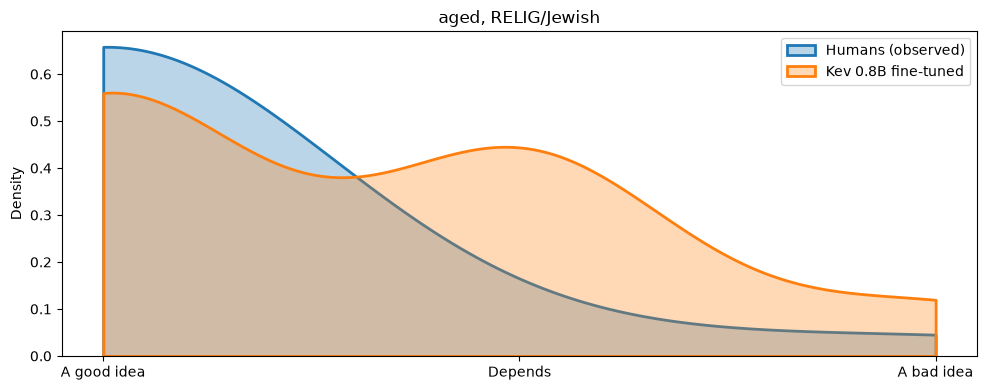

In [36]:
import textwrap
import matplotlib.pyplot as plt
import seaborn as sns

SEED = 0   # change to pick another question

likert_rows = [i for i, (group, v) in enumerate(labels) if predictions[next(iter(MODELS))][i]["type"] == "score"]
i = likert_rows[int(np.random.default_rng(SEED).integers(len(likert_rows)))]
group, v = labels[i]
record = next(r for r in test_records if r["group"] == group and v in r["questions"])
question = record["questions"][v]

shares = {"Humans (observed)": predictions[next(iter(MODELS))][i]["target"]}
shares |= {name: predictions[name][i]["probs"] for name in MODELS}

print("Persona:", ", ".join(f"{key}: {value}" for key, value in record["persona"].items()))
print("Question", v + ":", textwrap.fill(question["instructions"], 110))
for name in MODELS:
    print(f"{name}: {percent_of_range(shares['Humans (observed)'], shares[name]):.1f}% of the scale range")

levels = np.arange(len(question["criteria"]))
fig, ax = plt.subplots(figsize=(10, 4))
for name, p in shares.items():   # every distribution as a smoothed curve over the answer levels, filled and see-through
    sns.kdeplot(x=levels, weights=p.numpy(), bw_adjust=0.5, cut=0, fill=True, alpha=0.3, linewidth=2, label=name, ax=ax)
ax.set_xticks(levels, [textwrap.fill(level, 18) for level in question["criteria"]])
ax.set_ylabel("Density")   # smoothed: the area under each curve is the probability
ax.set_title(f"{v}, {group.removeprefix('SUBPOP/')}")
ax.legend()
plt.tight_layout()
plt.show()

## Two group contrasts on a test question

SubPOP gives answer distributions for single-attribute US groups, not crossed groups, so the panels are two contrasts on the same question: party (top row) and race (bottom row). The question was chosen because the human groups differ most in both rows (largest smaller-of-the-two gap among the test set's Likert questions), not by how well any model does. Neither model was trained on it.

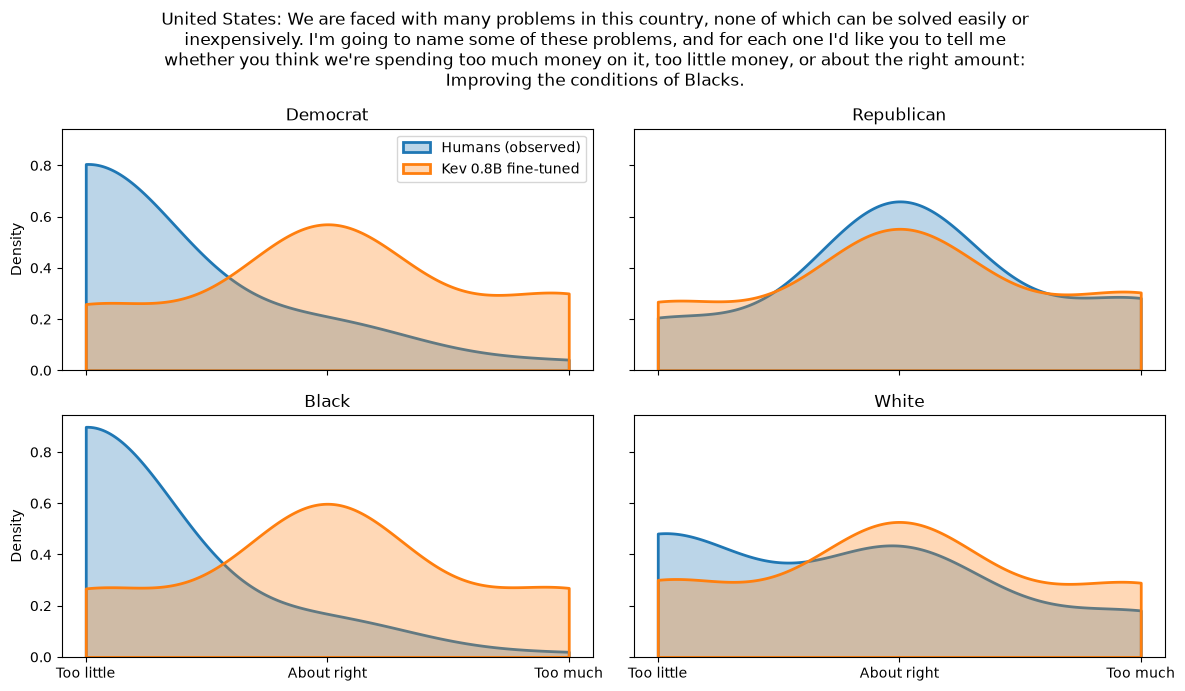

In [38]:
GRID_PANELS = [["POLPARTY/Democrat", "POLPARTY/Republican"],   # top row: party
               ["RACE/Black", "RACE/White"]]                   # bottom row: race

position = {(group, v): i for i, (group, v) in enumerate(labels)}   # (group, question) -> its row in the predictions

def plot_contrasts(v):
    """The observed and predicted answer distributions of question v, one panel per group in GRID_PANELS."""
    fig, axes = plt.subplots(len(GRID_PANELS), len(GRID_PANELS[0]), figsize=(12, 7), sharex=True, sharey=True)
    for row, row_axes in zip(GRID_PANELS, axes):
        for group, ax in zip(row, row_axes):
            i = position[f"SUBPOP/{group}", v]
            curves = {"Humans (observed)": predictions[next(iter(MODELS))][i]["target"]}
            curves |= {name: predictions[name][i]["probs"] for name in MODELS}
            levels = np.arange(len(curves["Humans (observed)"]))
            for name, p in curves.items():
                sns.kdeplot(x=levels, weights=p.numpy(), bw_adjust=0.5, cut=0, fill=True, alpha=0.3, linewidth=2, label=name, ax=ax)
            ax.set_title(group.split("/")[1])
            ax.set_ylabel("Density")
    question = next(r for r in test_records if v in r["questions"])["questions"][v]
    for ax in axes[-1]:
        ax.set_xticks(levels, [textwrap.fill(level, 14) for level in question["criteria"]])
    axes[0, 0].legend()
    fig.suptitle("United States: " + textwrap.fill(question["instructions"], 100))
    plt.tight_layout()
    plt.show()

plot_contrasts("natrace")   # spending on improving the conditions of Black people: too little, about right, too much

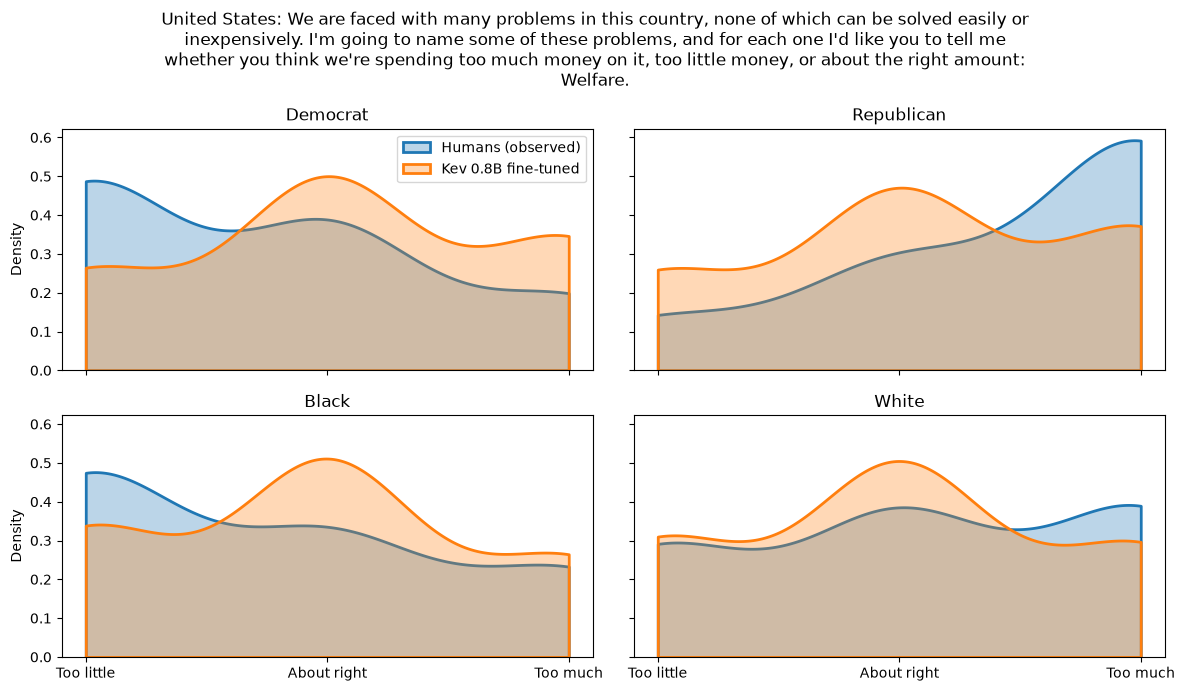

In [39]:
plot_contrasts("natfare")   # spending on welfare: second-largest party and race gaps

## Does the fine-tuned model use gender? One ISSP question

One ISSP training question on which women and men answer very differently: how household work is shared with the partner (ISSP 2022 v45; the largest average gap between women and men among all ISSP Likert questions). Three panels for France (everyone living with a partner, as the question asks): men (observed vs fine-tuned), women (observed vs fine-tuned), and the fine-tuned prediction with no `Sex` line in the persona. The records are aggregated from the respondent data by the training sampler (`IsspSampler.group`). This record was in the training data, so it shows what the model learned, not how it generalises.

runs/issp-all-0.8b-v8/best: loaded from runs/predictions
Persona: Country: France, Lives with a spouse or partner: Yes + Sex
Question: Which of the following best applies to the sharing of household work between you and your spouse/partner?


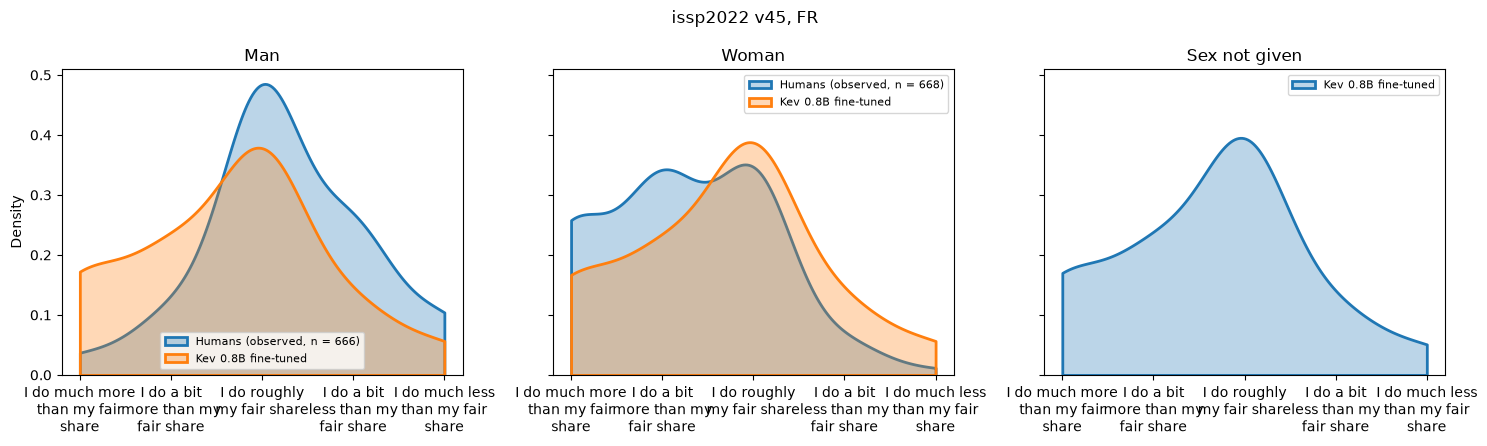

In [32]:
from issp_sampler import IsspSampler

EX_DATASET, EX_V, EX_COUNTRY = "issp2022", "v45", "FR"   # sharing of household work with the spouse/partner; France
EX_MODEL = "Kev 0.8B fine-tuned"

ex_sampler = IsspSampler([EX_DATASET])
ex_records = {"Man": ex_sampler.group(EX_DATASET, EX_COUNTRY, {"Sex": "Male"}, [EX_V]),
              "Woman": ex_sampler.group(EX_DATASET, EX_COUNTRY, {"Sex": "Female"}, [EX_V]),
              "Sex not given": ex_sampler.group(EX_DATASET, EX_COUNTRY, {}, [EX_V])}
ex_set = f"{EX_DATASET} {EX_V} sex"
ex_predictions = cached_predictions(MODELS[EX_MODEL], {ex_set: list(ex_records.values())})[ex_set]   # one row per record, in order

men = ex_records["Man"]
no_sex = ex_records["Sex not given"]["persona"]
question = men["questions"][EX_V]
print("Persona:", ", ".join(f"{key}: {value}" for key, value in no_sex.items()), "+ Sex")
print("Question:", textwrap.fill(question["instructions"], 110))
levels = np.arange(len(question["criteria"]))
fig, axes = plt.subplots(1, len(ex_records), figsize=(15, 4.5), sharex=True, sharey=True)
for (name, record), row, ax in zip(ex_records.items(), ex_predictions, axes):
    curves = {EX_MODEL: row["probs"]}
    if name != "Sex not given":   # humans: the stored record's observed shares
        curves = {f"Humans (observed, n = {record['n'][EX_V]})": row["target"], **curves}
    for label, p in curves.items():
        sns.kdeplot(x=levels, weights=p.numpy(), bw_adjust=0.5, cut=0, fill=True, alpha=0.3, linewidth=2, label=label, ax=ax)
    ax.set_xticks(levels, [textwrap.fill(level, 14) for level in question["criteria"]])
    ax.set_ylabel("Density")
    ax.set_title(name)
    ax.legend(fontsize=8)
fig.suptitle(f"{EX_DATASET} {EX_V}, {EX_COUNTRY}")
plt.tight_layout()
plt.show()